In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

In [2]:
df = pd.read_csv("../data/processed/heart_clean.csv")
df.head()

X = df.drop("target", axis=1)
y = df["target"]
print(X.shape)
print(y.shape)

(303, 13)
(303,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

(242, 13)
(61, 13)


Metrics for Logistic Regression:
Accuracy: 0.8688524590163934
Precision: 0.8125
Recall: 0.9285714285714286
F1 Score: 0.8666666666666667
ROC AUC: 0.9512987012987013


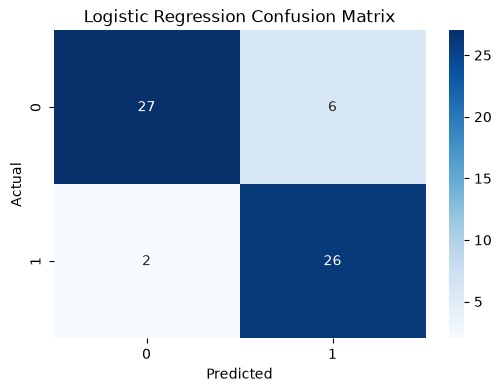

In [4]:
lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_test_scaled)

print("Metrics for Logistic Regression:")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

y_prob_lr = lr.predict_proba(X_test_scaled)[:,1]
roc_lr = roc_auc_score(y_test, y_prob_lr)
print("ROC AUC:", roc_lr)

cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [5]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Metrics for Random Forest:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
y_prob_rf = rf.predict_proba(X_test)[:,1]
roc_rf = roc_auc_score(y_test, y_prob_rf)
print("ROC AUC:", roc_rf)

Metrics for Random Forest:
Accuracy: 0.9016393442622951
Precision: 0.84375
Recall: 0.9642857142857143
F1 Score: 0.9
ROC AUC: 0.9545454545454546


In [6]:
lr_cv = cross_val_score(
    lr,
    X_scaled,
    y,
    cv=5,
    scoring='roc_auc'
)

print("Logistic Regression CV Scores:")
print(lr_cv)

print("Mean ROC-AUC:")
print(lr_cv.mean())

rf_cv = cross_val_score(
    rf,
    X,
    y,
    cv=5,
    scoring='roc_auc'
)

print("Random Forest CV Scores:")
print(rf_cv)

print("Mean ROC-AUC:")
print(rf_cv.mean())

print(f"Logistic Regression Mean ROC-AUC: {lr_cv.mean():.4f}")
print(f"Random Forest Mean ROC-AUC: {rf_cv.mean():.4f}")

Logistic Regression CV Scores:
[0.89177489 0.9469697  0.88636364 0.90347924 0.87834821]
Mean ROC-AUC:
0.901387135241302
Random Forest CV Scores:
[0.89393939 0.95400433 0.89556277 0.89225589 0.86886161]
Mean ROC-AUC:
0.9009247985810486
Logistic Regression Mean ROC-AUC: 0.9014
Random Forest Mean ROC-AUC: 0.9009


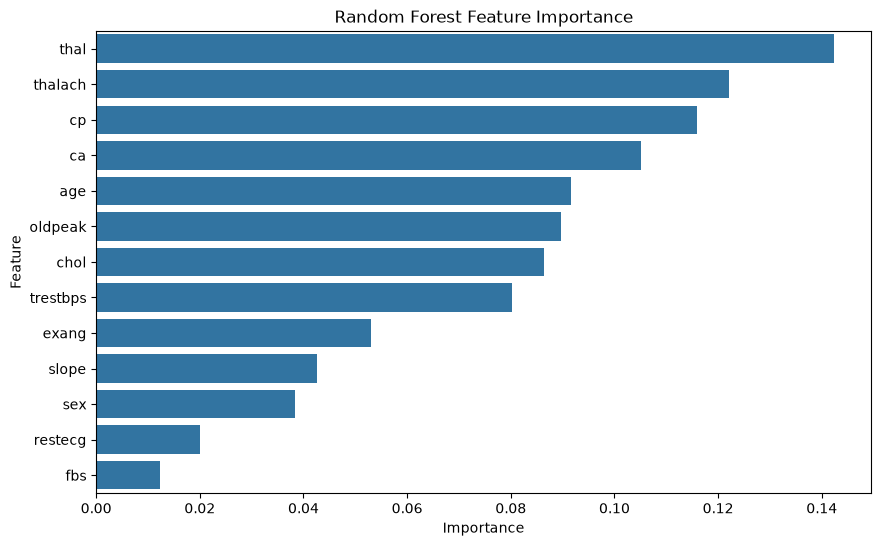

In [7]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        by='Importance',
        ascending=False
    )
)

feature_importance

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title("Random Forest Feature Importance")

plt.show()

In [8]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    "ROC_AUC": [
        roc_lr,
        roc_rf
    ]
})

results

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.868852,0.951299
1,Random Forest,0.901639,0.954545


Model Selection

Two machine learning algorithms were evaluated:
1. Logistic Regression
2. Random Forest

Logistic Regression was selected as a baseline due to its simplicity and interpretability.

Random Forest was selected because it can model nonlinear feature interactions and is robust to outliers.

Based on evaluation metrics and cross-validation performance, Random Forest achieved superior predictive performance and was therefore selected as the final model for deployment.